=== NGƯỠNG (THRESHOLD) = 0.5 ===
Số ca máy đoán là Mắc bệnh (1): 20/40
Độ chính xác (Accuracy): 90.00%
Ma trận nhầm lẫn:
[[18  2]
 [ 2 18]]

=== NGƯỠNG (THRESHOLD) = 0.6 ===
Số ca máy đoán là Mắc bệnh (1): 19/40
Độ chính xác (Accuracy): 87.50%
Ma trận nhầm lẫn:
[[18  2]
 [ 3 17]]

=== NGƯỠNG (THRESHOLD) = 0.7 ===
Số ca máy đoán là Mắc bệnh (1): 19/40
Độ chính xác (Accuracy): 87.50%
Ma trận nhầm lẫn:
[[18  2]
 [ 3 17]]

=== NGƯỠNG (THRESHOLD) = 0.8 ===
Số ca máy đoán là Mắc bệnh (1): 17/40
Độ chính xác (Accuracy): 87.50%
Ma trận nhầm lẫn:
[[19  1]
 [ 4 16]]



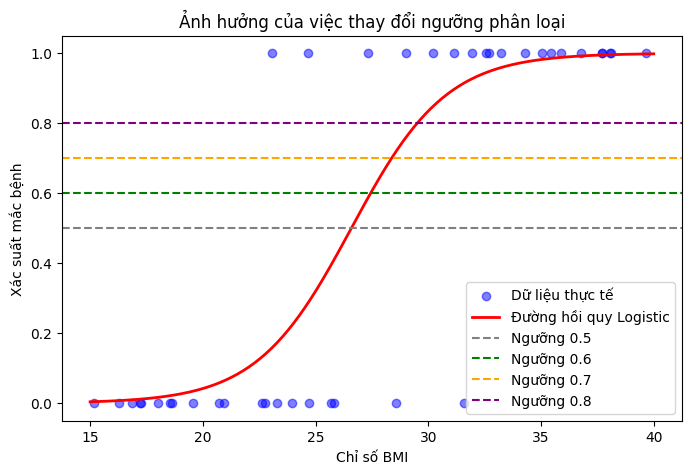

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)
bmi = np.random.uniform(15, 40, 200).reshape(-1, 1)
xac_suat_thuc = 1 / (1 + np.exp(-0.5 * (bmi.ravel() - 27)))
mac_benh = (np.random.rand(200) < xac_suat_thuc).astype(int)

X_train, X_test, y_train, y_test = train_test_split(bmi, mac_benh, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_xac_suat = model.predict_proba(X_test)[:, 1]

cac_nguong = [0.5, 0.6, 0.7, 0.8]

for nguong in cac_nguong:
    y_pred = (y_xac_suat >= nguong).astype(int)

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    print(f"=== NGƯỠNG (THRESHOLD) = {nguong} ===")
    print(f"Số ca máy đoán là Mắc bệnh (1): {y_pred.sum()}/{len(y_test)}")
    print(f"Độ chính xác (Accuracy): {acc * 100:.2f}%")
    print("Ma trận nhầm lẫn:")
    print(cm)
    print()

bmi_ve = np.linspace(15, 40, 300).reshape(-1, 1)
duong_sigmoid = model.predict_proba(bmi_ve)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="blue", alpha=0.5, label="Dữ liệu thực tế")
plt.plot(bmi_ve, duong_sigmoid, color="red", linewidth=2, label="Đường hồi quy Logistic")

mau_sac = ["gray", "green", "orange", "purple"]
for nguong, mau in zip(cac_nguong, mau_sac):
    plt.axhline(nguong, color=mau, linestyle="--", label=f"Ngưỡng {nguong}")

plt.title("Ảnh hưởng của việc thay đổi ngưỡng phân loại")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.show()